In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [8]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import os

def find_file(filename, search_path='/content/drive'):
    results = []
    for root, dirs, files in os.walk(search_path):
        if filename in files:
            results.append(os.path.join(root, filename))
    return results

# 'galaxy-pair-noisy.tif' 파일의 실제 위치 검색
found_paths = find_file('galaxy-pair-noisy.tif')
if found_paths:
    print("파일을 찾았습니다! 실제 경로:")
    for path in found_paths:
        print(path)
else:
    print("구글 드라이브에서 'galaxy-pair-noisy.tif' 파일을 찾을 수 없습니다.")
    print("드라이브 마운트 후 동기화에 시간이 걸릴 수 있으니 잠시 후 다시 실행해 보시거나, 파일명을 다시 확인해 주세요.")

파일을 찾았습니다! 실제 경로:
/content/drive/MyDrive/DIP4E/galaxy-pair-noisy.tif


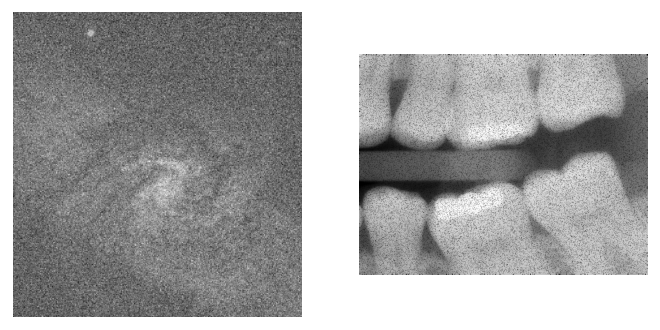

In [9]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

In [10]:
SS = 5 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f1))
r_mean = np.zeros(np.shape(f1))
r_mean_r = np.zeros(np.shape(f2))
r_median_r = np.zeros(np.shape(f2))

In [11]:
f1_r = r_mean
f2_r = r_median_r
for x in range (SS,np.size(f1,0)-ss):
  for y in range (SS,np.size(f1,1)-ss):
    Sxy = f1[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    r_median[x,y] = np.median(Sxy)
for x in range (SS,np.size(f2,0)-ss):
  for y in range (SS,np.size(f2,1)-ss):
    Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean_r[x,y] = np.mean(Sxy)
    r_median_r[x,y] = np.median(Sxy)

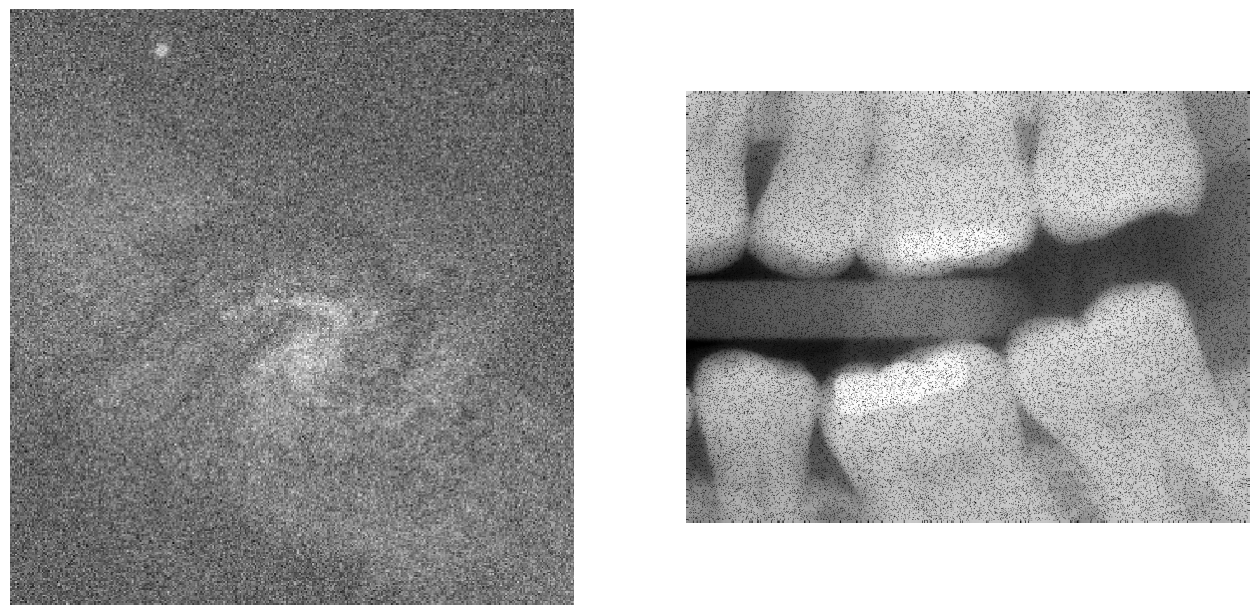

In [12]:
plt.figure(figsize=(16,9))
plt.subplot(121)
plt.imshow(f1,cmap='gray',aspect='equal')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray',aspect='equal')
plt.axis('off')
plt.show()

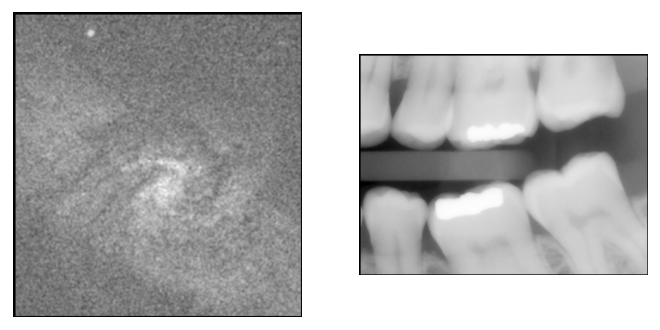

In [13]:
# f1_r: denoised f1
# f2_r: denoised f2
plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1_r,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2_r,cmap='gray')
plt.axis('off')
plt.show()

In [14]:
# Adaptive Median Filtering
#f = f_sp
f = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')
SS_vals = np.array([3, 5, 7])
r_amedian = np.zeros(np.shape(f))
r_median = np.zeros(np.shape(f))
r_case = np.zeros(np.shape(f))

ss_max = int((np.max(SS_vals)-1)/2)
for x in range(ss_max,np.size(f,0)-ss_max):
  for y in range(ss_max,np.size(f,1)-ss_max):
    flag_go = 1
    cnt = 0
    z_xy = f[x,y]
    for SS in SS_vals:
      ss = int((SS-1)/2)
      Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
      z_med = np.median(Sxy)
      z_min = np.min(Sxy)
      z_max = np.max(Sxy)

      if cnt==0:
        r_median[x,y] = z_med

      if z_min<z_med and z_med<z_max:
        if z_min<z_xy and z_xy<z_max:
          r_amedian[x,y] = z_xy
          flag_go = 0
        else:
          r_amedian[x,y] = z_med
          flag_go = 0
      else:
        if SS == np.max(SS_vals):
          r_amedian[x,y] = z_med
          flag_go = 0

      if flag_go==0:
        r_case[x,y] = cnt
        break
      cnt = cnt+1

In [16]:
plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray')
plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray')